### Q1. What is object tracking, and how does it differ from object detection?

**Object Tracking** is the computer vision task of locating a moving object (or multiple objects) over time across consecutive video frames while maintaining a consistent unique identity (ID) for each object.

**Key Differences between Object Detection and Object Tracking:**
* **Temporal Context:** Object detection processes each frame independently without memory of previous frames, whereas object tracking links detections across time to build trajectories.
* **Identity Assignment:** Detection outputs class labels and bounding boxes for objects in a single frame (e.g., `Person`, `Car`). Tracking assigns and preserves unique IDs across frames (e.g., `Person_1`, `Person_2`).
* **Handling Occlusions & Motion:** Detection fails when an object is temporarily occluded in a frame; tracking uses motion models (like Kalman Filters) to predict positions during brief occlusions.
* **Computational Efficiency:** Running a heavy detector on every frame can be computationally expensive, while tracking algorithms can predict intermediate positions rapidly between detection steps.

### Q2. Explain the basic working principle of a Kalman Filter.

A **Kalman Filter** is a recursive mathematical algorithm used to estimate the hidden internal state of a dynamic linear system (such as an object's true position and velocity) from a series of noisy measurements over time.

**Basic Working Principle:**
1. **Recursive Estimation:** Instead of storing all past data, it relies only on the previous state estimate and the current measurement, making it computationally lightweight and ideal for real-time systems.
2. **Two-Step Cycle (Predict & Update):**
   * **Predict:** Using a physical motion model (e.g., constant velocity), the filter projects the current state and its uncertainty forward to the next time step.
   * **Update (Correct):** When a new noisy sensor/detector measurement arrives, the filter computes a weighted average between the predicted state and the measured state.
3. **Kalman Gain:** The weighting factor—called the **Kalman Gain**—dynamically balances trust between the model's prediction and the sensor's measurement based on their respective uncertainties (covariances).

### Q3. What is YOLO, and why is it popular for object detection in real-time applications?

**YOLO (You Only Look Once)** is a family of single-stage, deep-learning-based object detection algorithms that frame object detection as a single regression problem—predicting bounding boxes and class probabilities directly from full images in a single forward pass.

**Why it is popular for real-time applications:**
* **Single-Pass Architecture:** Unlike two-stage detectors (e.g., Faster R-CNN) that first generate region proposals and then classify them, YOLO processes the entire image once, achieving high frames-per-second (FPS) rates.
* **Global Context Reasoning:** Because it looks at the entire image during training and inference, YOLO captures contextual information about classes and their appearance, reducing background false positives.
* **Scalability & Deployment:** Modern YOLO variants (YOLOv5, YOLOv8, YOLOv11) offer lightweight model sizes (Nano, Small) optimized for edge devices, GPUs, and mobile hardware without sacrificing strong accuracy.

### Q4. How does DeepSORT improve object tracking?

**DeepSORT (Simple Online and Realtime Tracking with a Deep Association Metric)** improves upon the original SORT algorithm by integrating **deep appearance descriptors** alongside motion estimation.

**Key Improvements:**
* **Reduced Identity Switches:** Standard SORT relies solely on bounding box overlap (IoU) and Kalman Filter motion predictions, causing frequent ID switches when objects cross paths or get occluded. DeepSORT extracts visual feature embeddings using a CNN to recognize objects by appearance.
* **Longer Occlusion Survival:** By matching appearance features when an object reappears after prolonged occlusion, DeepSORT successfully reconnects the object to its original track ID.
* **Matching Cascade:** It prioritizes tracks that were seen more recently when associating detections, preventing older, uncertain tracks from stealing detections from active tracks.

### Q5. Explain the concept of state estimation in a Kalman Filter.

**State Estimation** in a Kalman Filter is the process of inferring the true underlying variables (the **state vector**) of a moving object when those variables cannot be measured directly or are corrupted by noise.

* **State Vector ($x_k$):** Typically includes observable variables (like bounding box center coordinates $x, y$, aspect ratio, and height) as well as unobservable hidden variables (like velocities $\dot{x}, \dot{y}$).
* **Probabilistic Representation:** The Kalman Filter models the state as a multivariate Gaussian distribution defined by a **mean vector** (the best estimate of the state) and a **covariance matrix ($P_k$)** (representing the uncertainty or confidence in that estimate).
* By combining physics-based state transitions with noisy observations, state estimation filters out jitter and provides smooth, accurate trajectories.

### Q6. What are the challenges in object tracking across multiple frames?

Tracking objects consistently across video frames involves several core computer vision challenges:
* **Occlusions:** Objects frequently pass behind obstacles or other objects, temporarily disappearing from the detector's view.
* **Identity Switches:** When multiple similar-looking objects (e.g., players in uniform or crowded pedestrians) cross paths, trackers can confuse their identities.
* **Appearance Variations:** Changes in lighting, camera angle, object scale, deformation, or partial visibility alter how an object looks across frames.
* **Motion Blur & Fast Movement:** Rapid object movement or sudden camera motion causes large displacements between frames and blurred features, breaking overlap-based matching.
* **Detector Noise (False Positives/Negatives):** Missed detections or spurious bounding boxes from the upstream detector can prematurely terminate valid tracks or spawn ghost tracks.

### Q7. Describe the role of the Hungarian algorithm in DeepSORT.

The **Hungarian Algorithm** (also known as the Kuhn-Munkres algorithm) is a combinatorial optimization algorithm used in DeepSORT to solve the **data association problem**—matching newly detected bounding boxes in the current frame to existing predicted tracks.

* **Cost Matrix Construction:** DeepSORT builds a 2D cost matrix where rows represent existing tracks and columns represent new detections. Each cell contains a combined cost derived from **motion distance** (Mahalanobis distance) and **appearance distance** (cosine distance between feature embeddings).
* **Optimal One-to-One Assignment:** The Hungarian algorithm finds the optimal one-to-one assignment that minimizes the total association cost across all pairs, ensuring each detection is matched to at most one track (and vice versa), subject to gating thresholds.

### Q8. What are the advantages of using YOLO over traditional object detection methods?

Traditional object detection methods—such as Sliding Window + HOG/SIFT + SVM, or Selective Search + R-CNN—rely on hand-crafted features or multi-stage region proposal pipelines. YOLO offers significant advantages:

* **Orders-of-Magnitude Faster Inference:** Traditional sliding-window or region-proposal pipelines evaluate thousands of candidate patches per image. YOLO evaluates the image in a single neural network pass, enabling real-time video processing.
* **End-to-End Learning:** Instead of tuning separate feature extractors, classifiers, and bounding-box regressors independently, YOLO optimizes the entire detection pipeline jointly.
* **Better Generalization & Context:** Traditional sliding windows inspect isolated local patches and often mistake background textures for objects. YOLO sees the full image simultaneously, encoding global context and generalizing better to new domains.

### Q9. How does the Kalman Filter handle uncertainty in predictions?

The Kalman Filter explicitly tracks and propagates uncertainty using **covariance matrices** at every step:

* **State Covariance Matrix ($P$):** Quantifies the uncertainty in the current estimated state. Larger values indicate higher uncertainty.
* **Process Noise Covariance ($Q$):** Added during the **Predict** step ($P_{k|k-1} = F P_{k-1|k-1} F^T + Q$). It accounts for unpredictable real-world disturbances (e.g., an object suddenly accelerating or turning) that are not captured by the idealized motion model. As an object goes undetected across frames, $Q$ causes uncertainty $P$ to grow.
* **Measurement Noise Covariance ($R$):** Represents the inherent inaccuracy of the object detector/sensor.
* **Dynamic Weighting via Kalman Gain ($K$):** When updating, if prediction uncertainty $P$ is high relative to measurement noise $R$, $K$ increases so the filter trusts the new measurement more. Conversely, if the sensor is noisy ($R$ is large), $K$ decreases and the filter relies more on its smooth motion prediction.

### Q10. What is the difference between object tracking and object segmentation?

| Aspect | Object Tracking | Object Segmentation |
| :--- | :--- | :--- |
| **Primary Goal** | Follow objects across time and maintain consistent unique IDs across video frames. | Partition an image into meaningful regions by classifying every pixel belonging to objects. |
| **Output Format** | Bounding boxes (or trajectories) paired with persistent Track IDs over time. | Pixel-level binary masks or semantic class maps for each pixel in an image. |
| **Temporal Dimension** | Inherently temporal (operates across sequential video frames). | Primarily spatial (typically operates on individual images/frames, unless extended to Video Object Segmentation). |
| **Granularity** | Coarse spatial localization (rectangular box around the object). | Fine-grained, exact pixel-level object boundaries. |

### Q11. How can YOLO be used in combination with a Kalman Filter for tracking?

Combining **YOLO** and a **Kalman Filter** forms the classic **Tracking-by-Detection** pipeline (the foundation of algorithms like SORT):

1. **Detection (YOLO):** On frame $t$, YOLO scans the image and outputs bounding boxes $[x, y, w, h]$ and class labels for detected objects.
2. **State Prediction (Kalman Filter):** Simultaneously, every active track uses its dedicated Kalman Filter to predict where its target object should be in frame $t$ based on prior position and velocity.
3. **Data Association:** Predicted boxes from the Kalman Filters are compared against YOLO's new detections using metrics like Intersection over Union (IoU) and matched via the Hungarian algorithm.
4. **State Update & Track Management:**
   * **Matched pairs:** The Kalman Filter updates its state and velocity estimates using the matched YOLO bounding box as the new measurement.
   * **Unmatched detections:** Initialize new Kalman Filter tracks.
   * **Unmatched tracks:** Retain their Kalman Filter predicted positions for a few frames (handling brief missed detections) before deleting them if they remain lost.

### Q12. What are the key components of DeepSORT?

DeepSORT consists of four primary components working together:

1. **Object Detector (e.g., YOLO):** Provides per-frame bounding box detections and confidence scores.
2. **Kalman Filter (Motion Model):** Predicts the future bounding box position and velocity of each tracked object using an 8-dimensional state space $(u, v, \gamma, h, \dot{u}, \dot{v}, \dot{\gamma}, \dot{h})$.
3. **Deep Appearance Feature Extractor (CNN):** A pre-trained convolutional neural network (trained on person/object re-identification datasets) that crops each detected bounding box and extracts a normalized 128-dimensional appearance embedding vector.
4. **Data Association Module (Matching Cascade + Hungarian Algorithm + IoU Matching):** Combines Mahalanobis distance (motion) and Cosine distance (appearance) to optimally match new detections to existing tracks while managing track lifecycles (`Tentative`, `Confirmed`, `Deleted`).

### Q13. Explain the process of associating detections with existing tracks in DeepSORT.

DeepSORT associates new detections with existing tracks through a multi-stage pipeline:

1. **Gating (Feasibility Filtering):**
   * **Motion Gate:** Computes the squared **Mahalanobis distance** between predicted Kalman states and detected boxes, discarding pairs that exceed a 95% confidence threshold ($\chi^2$ distribution).
   * **Appearance Gate:** Computes the minimum **Cosine distance** between the detection's 128-D feature vector and the track's gallery of recent appearance embeddings, discarding pairs exceeding an appearance threshold.
2. **Combined Cost Metric:** For valid pairs passing both gates, a weighted sum of normalized Mahalanobis distance and Cosine distance forms the association cost.
3. **Matching Cascade:** Instead of matching all tracks at once, DeepSORT runs the Hungarian algorithm iteratively by track age—matching tracks seen 1 frame ago first, then 2 frames ago, up to `max_age`. This gives priority to active, high-confidence tracks.
4. **IoU Fallback Matching:** Any remaining unmatched detections and unconfirmed/recently lost tracks (age = 1) undergo a final Intersection-over-Union (IoU) matching step via the Hungarian algorithm to handle sudden appearance changes.

### Q14. Why is real-time tracking important in many applications?

Real-time tracking (processing video streams with minimal latency, typically $\ge 30$ FPS) is critical whenever decisions or actions must occur immediately as events unfold:

* **Autonomous Driving & ADAS:** Self-driving vehicles must continuously predict the trajectories of surrounding cars, cyclists, and pedestrians in milliseconds to execute safe braking, lane changes, and collision avoidance.
* **Video Surveillance & Public Safety:** Security systems require instant alerts for unauthorized intrusion, perimeter breaches, or suspicious crowd behavior rather than post-event forensic review.
* **Robotics & Drones:** Autonomous robots and UAVs rely on real-time tracking for dynamic obstacle avoidance, human-following, and object manipulation.
* **Sports Analytics & Broadcasting:** Live broadcasts use real-time player and ball tracking to generate instant tactical overlays, speed metrics, and automated camera framing.

### Q15. Describe the prediction and update steps of a Kalman Filter.

The Kalman Filter operates iteratively through two mathematical stages at every time step $k$:

**1. Prediction Step (Time Update):**
Projects the previous state estimate and error covariance forward in time using the system's motion model:
* **Predicted State Estimate:** $\hat{x}_{k|k-1} = F_k \hat{x}_{k-1|k-1} + B_k u_k$
* **Predicted Error Covariance:** $P_{k|k-1} = F_k P_{k-1|k-1} F_k^T + Q_k$
*(where $F_k$ is the state transition matrix, $B_k u_k$ is optional control input, and $Q_k$ is process noise covariance).*

**2. Update Step (Measurement Correction):**
Incorporates the new measurement $z_k$ to refine the predicted state:
* **Innovation (Measurement Residual):** $\tilde{y}_k = z_k - H_k \hat{x}_{k|k-1}$
* **Innovation Covariance:** $S_k = H_k P_{k|k-1} H_k^T + R_k$
* **Kalman Gain:** $K_k = P_{k|k-1} H_k^T S_k^{-1}$
* **Updated State Estimate:** $\hat{x}_{k|k} = \hat{x}_{k|k-1} + K_k \tilde{y}_k$
* **Updated Error Covariance:** $P_{k|k} = (I - K_k H_k) P_{k|k-1}$
*(where $H_k$ is the observation matrix and $R_k$ is measurement noise covariance).*

### Q16. What is a bounding box, and how does it relate to object tracking?

A **bounding box** is a rectangular frame defined by pixel coordinates—commonly represented as $(x_{\min}, y_{\min}, x_{\max}, y_{\max})$ or center coordinates with width and height $(c_x, c_y, w, h)$—that tightly encloses a detected object in an image.

**How it relates to object tracking:**
* **State Representation:** In 2D visual tracking, the bounding box parameters (center position, scale/area, aspect ratio, and their velocities) serve directly as the state variables tracked by filters like the Kalman Filter.
* **Spatial Association Metric:** Trackers measure bounding box overlap via **Intersection over Union (IoU)** between predicted boxes and new detections to link the same object across consecutive frames.
* **Appearance Cropping:** Feature extractors (like the CNN in DeepSORT) use bounding box coordinates to crop the target object's pixels from the frame for visual embedding extraction.

### Q17. What is the purpose of combining object detection and tracking in a pipeline?

Combining object detection and tracking (known as **Tracking-by-Detection**) leverages the complementary strengths of both paradigms to achieve robust, efficient video understanding:

* **Persistent Identity Over Time:** Detectors locate *what* is in a frame and *where* it is, while trackers connect those detections across frames to answer *where each specific individual went*.
* **Resilience to Missed Detections:** If the detector briefly fails due to occlusion, motion blur, or lighting changes, the tracker bridges the gap using motion prediction.
* **Trajectory & Behavior Analysis:** Linking detections yields velocity vectors, paths, dwell times, and counting metrics (e.g., counting vehicles crossing a line without double-counting).
* **Computational Optimization:** Detection can optionally be run every $N$ frames while lightweight tracking interpolates positions on intermediate frames, boosting overall system throughput.

### Q18. What is the role of the appearance feature extractor in DeepSORT?

The **appearance feature extractor** in DeepSORT is a deep Convolutional Neural Network (CNN) trained on large-scale re-identification (Re-ID) datasets to capture the visual identity of objects.

**Its key roles include:**
* **Visual Embedding Generation:** For every detected bounding box, it crops the image patch and compresses its visual characteristics (clothing color, texture, shape) into a compact, L2-normalized **128-dimensional feature vector**.
* **Re-Identification After Occlusion:** When an object disappears behind an obstacle and re-emerges several frames later—where motion predictions alone become too uncertain—the extractor allows DeepSORT to match the new detection against stored feature galleries using **cosine distance**.
* **Disambiguating Crossing Paths:** When two objects pass close to each other, visual features prevent their track IDs from swapping.

### Q19. How do occlusions affect object tracking, and how can Kalman Filter help mitigate this?

**How Occlusions Affect Tracking:**
* **Loss of Measurements:** When an object is blocked by another object or background structure, the object detector fails to produce a bounding box for it.
* **Track Fragmentation & ID Switches:** Without new detections, naive trackers terminate the track prematurely and assign a brand-new ID when the object reappears, or mistakenly associate the track with the occluding object.

**How the Kalman Filter Mitigates Occlusions:**
* **Inertia-Based Trajectory Projection:** Because the Kalman Filter estimates an object's velocity ($\dot{x}, \dot{y}$) alongside its position, it continues running its **Predict** step during frames without detections—projecting the object's path smoothly behind the obstacle.
* **Re-Acquisition Window:** By maintaining the predicted bounding box for a configurable number of frames (`max_age`), when the object emerges on the other side of the obstacle, its predicted position closely aligns with the newly reappeared detection, enabling seamless re-association.

### Q20. Explain how YOLO's architecture is optimized for speed.

YOLO achieves high inference speed through several architectural design choices:

* **Single-Stage Unified Network:** Eliminates separate region proposal networks (RPN) and per-region classification heads. A single CNN backbone and detection head predict all bounding boxes and class probabilities simultaneously in one forward pass.
* **Grid-Based Spatial Division:** Divides the input image into an $S \times S$ grid where each grid cell is directly responsible for predicting objects centered within it, parallelizing predictions cleanly on GPUs.
* **Efficient Backbone & Neck Designs:** Uses lightweight building blocks such as Darknet residual blocks, CSPNet (Cross Stage Partial connections), depthwise separable convolutions, and efficient Feature Pyramid Networks (FPN/PANet) to minimize FLOPs and memory access overhead.
* **Anchor-Free Decoupled Heads (Modern YOLOs):** Removes complex anchor-box matching computations during inference, directly predicting box offsets and class scores with streamlined convolutional layers.

### Q21. What is a motion model, and how does it contribute to object tracking?

A **motion model** is a mathematical formulation that describes how an object's kinematic state (position, velocity, acceleration, scale) evolves from one time step to the next (e.g., Constant Velocity model or Constant Acceleration model).

**Contributions to Object Tracking:**
* **Future Position Prediction:** Narrows down the search region in the next frame by predicting where an object is likely to appear.
* **Gating Impossible Matches:** Prevents physically implausible associations (e.g., matching a pedestrian on the left side of the frame to a detection on the far right side in a single frame).
* **Trajectory Smoothing:** Filters out frame-to-frame bounding box jitter caused by noisy detections, producing smooth motion paths and reliable velocity estimates.

### Q22. How can the performance of an object tracking system be evaluated?

Multi-Object Tracking (MOT) systems are evaluated against ground-truth annotated video datasets (such as MOT17, MOT20, or DanceTrack) using standard benchmark metrics:

* **MOTA (Multiple Object Tracking Accuracy):** Combines three error sources—False Positives (FP), False Negatives/Missed Targets (FN), and Identity Switches (IDSW)—normalized by the total number of ground-truth objects:
  $$\text{MOTA} = 1 - \frac{\sum_t (\text{FN}_t + \text{FP}_t + \text{IDSW}_t)}{\sum_t \text{GT}_t}$$
* **MOTP (Multiple Object Tracking Precision):** Measures the average spatial alignment (IoU or center distance) between predicted bounding boxes and ground-truth boxes for matched detections.
* **IDF1 (ID F1 Score):** Evaluates identity preservation over time by computing the harmonic mean of ID Precision and ID Recall—measuring how long a tracker correctly follows the same object with a consistent ID.
* **HOTA (Higher Order Tracking Accuracy):** Balances detection accuracy (DetA) and association accuracy (AssA) equally across multiple IoU thresholds, providing a unified view of both localization and identity tracking.
* **Runtime Speed (FPS):** Measures inference throughput (frames per second) to verify real-time feasibility.

### Q23. What are the key differences between DeepSORT and traditional tracking algorithms?

| Feature | Traditional Tracking (e.g., Optical Flow, Meanshift, KCF, SORT) | DeepSORT |
| :--- | :--- | :--- |
| **Feature Representation** | Hand-crafted low-level features (color histograms, HOG, pixel intensity gradients) or pure bounding-box geometry (SORT). | Deep learning-based 128-D visual appearance embeddings learned via CNNs combined with kinematic states. |
| **Occlusion Handling** | Poor; tracks easily drift onto background clutter or lose targets during full occlusion. | Strong; re-identifies objects after extended occlusions using stored appearance feature galleries. |
| **Multi-Object Scaling** | Single-object trackers (e.g., KCF, CSRT) require running independent trackers per object, slowing down with crowd size. | Built for multi-object tracking; batches CNN feature extraction and solves global assignment efficiently. |
| **Identity Persistence** | Frequent ID switches when similar objects cross paths. | High ID consistency via combined Mahalanobis (motion) + Cosine (appearance) matching cascade. |

In [8]:
# Practical 1: Implement a Kalman filter to predict and update the state of an object given its measurements.

import numpy as np

class KalmanFilter1D:
    def __init__(self, dt=1.0, process_var=1e-2, measurement_var=1e-1):
        # State vector: [position, velocity]
        self.x = np.array([[0.0], [0.0]])
        # State transition matrix (constant velocity model)
        self.F = np.array([[1.0, dt],
                           [0.0, 1.0]])
        # Observation matrix (we measure position directly)
        self.H = np.array([[1.0, 0.0]])
        # Covariance matrices
        self.P = np.eye(2) * 1.0
        self.Q = np.eye(2) * process_var
        self.R = np.array([[measurement_var]])

    def predict(self):
        self.x = self.F @ self.x
        self.P = self.F @ self.P @ self.F.T + self.Q
        return self.x.flatten()

    def update(self, z):
        z = np.array([[z]])
        y = z - (self.H @ self.x)                      # Innovation
        S = self.H @ self.P @ self.H.T + self.R        # Innovation covariance
        K = self.P @ self.H.T @ np.linalg.inv(S)       # Kalman Gain
        self.x = self.x + (K @ y)                      # Updated state
        I = np.eye(self.F.shape[0])
        self.P = (I - K @ self.H) @ self.P             # Updated covariance
        return self.x.flatten()

# Example usage with noisy position measurements
kf = KalmanFilter1D(dt=1.0, process_var=0.01, measurement_var=0.25)
measurements = [1.1, 1.9, 3.2, 3.8, 5.1, 6.0]

print("Step | Measurement | Predicted Pos | Updated State (Pos, Vel)")
print("-" * 62)
for step, z in enumerate(measurements, start=1):
    pred = kf.predict()
    updated = kf.update(z)
    print(f"{step:4d} | {z:11.2f} | {pred[0]:13.3f} | ({updated[0]:.3f}, {updated[1]:.3f})")

Step | Measurement | Predicted Pos | Updated State (Pos, Vel)
--------------------------------------------------------------
   1 |        1.10 |         0.000 | (0.978, 0.487)
   2 |        1.90 |         1.465 | (1.814, 0.719)
   3 |        3.20 |         2.533 | (3.023, 0.966)
   4 |        3.80 |         3.989 | (3.865, 0.916)
   5 |        5.10 |         4.781 | (4.970, 0.980)
   6 |        6.00 |         5.950 | (5.977, 0.989)


In [9]:
# Practical 2: Write a function to normalize an image array such that pixel values are scaled between 0 and 1.

import numpy as np

def normalize_image(image_array: np.ndarray) -> np.ndarray:
    """Scales image pixel values to the [0, 1] float32 range."""
    img = image_array.astype(np.float32)
    min_val = img.min()
    max_val = img.max()
    if max_val > min_val:
        return (img - min_val) / (max_val - min_val)
    return np.zeros_like(img, dtype=np.float32)

# Example usage with a dummy 4x4x3 RGB image (0-255 pixel range)
np.random.seed(42)
dummy_image = np.random.randint(0, 256, size=(4, 4, 3), dtype=np.uint8)
normalized_image = normalize_image(dummy_image)

print("Original dtype & range  :", dummy_image.dtype, f"[{dummy_image.min()}, {dummy_image.max()}]")
print("Normalized dtype & range:", normalized_image.dtype, f"[{normalized_image.min():.4f}, {normalized_image.max():.4f}]")

Original dtype & range  : uint8 [3, 245]
Normalized dtype & range: float32 [0.0000, 1.0000]


In [10]:
# Practical 3: Create a function to generate dummy object detection data with confidence scores and bounding boxes.
# Filter the detections based on a confidence threshold.

import numpy as np

def generate_dummy_detections(num_detections=8, img_width=640, img_height=480, seed=42):
    """Generates dummy detections in format: [x1, y1, x2, y2, confidence, class_id]."""
    rng = np.random.default_rng(seed)
    detections = []
    for _ in range(num_detections):
        x1 = rng.integers(0, img_width - 100)
        y1 = rng.integers(0, img_height - 100)
        w = rng.integers(30, 120)
        h = rng.integers(30, 120)
        x2 = min(img_width, x1 + w)
        y2 = min(img_height, y1 + h)
        conf = round(float(rng.uniform(0.1, 0.99)), 3)
        cls_id = int(rng.integers(0, 5))
        detections.append([int(x1), int(y1), int(x2), int(y2), conf, cls_id])
    return detections

def filter_detections(detections, conf_threshold=0.5):
    """Filters detections whose confidence score meets or exceeds conf_threshold."""
    return [det for det in detections if det[4] >= conf_threshold]

# Example usage
raw_detections = generate_dummy_detections(num_detections=8, seed=42)
filtered = filter_detections(raw_detections, conf_threshold=0.5)

print(f"Total generated detections: {len(raw_detections)}")
for d in raw_detections:
    print(" ", d)

print(f"\nFiltered detections (conf >= 0.5): {len(filtered)}")
for d in filtered:
    print(" ", d)

Total generated detections: 8
  [48, 294, 136, 363, 0.864, 0]
  [376, 76, 414, 153, 0.777, 4]
  [387, 298, 463, 339, 0.501, 2]
  [200, 69, 313, 169, 0.832, 3]
  [294, 168, 364, 218, 0.594, 4]
  [34, 326, 138, 380, 0.775, 3]
  [378, 134, 414, 251, 0.895, 3]
  [420, 288, 467, 350, 0.139, 2]

Filtered detections (conf >= 0.5): 7
  [48, 294, 136, 363, 0.864, 0]
  [376, 76, 414, 153, 0.777, 4]
  [387, 298, 463, 339, 0.501, 2]
  [200, 69, 313, 169, 0.832, 3]
  [294, 168, 364, 218, 0.594, 4]
  [34, 326, 138, 380, 0.775, 3]
  [378, 134, 414, 251, 0.895, 3]


In [11]:
# Practical 4: Write a function that takes a list of YOLO detections and extracts a random 128-dimensional feature vector for each detection.

import numpy as np

def extract_128d_features(yolo_detections, seed=42):
    """
    Takes a list of YOLO detections [x1, y1, x2, y2, conf, class_id]
    and returns a list of L2-normalized 128-dimensional feature vectors.
    """
    rng = np.random.default_rng(seed)
    features = []
    for _ in yolo_detections:
        vec = rng.standard_normal(128).astype(np.float32)
        # L2-normalize as done in DeepSORT appearance embeddings
        norm = np.linalg.norm(vec)
        vec = vec / norm if norm > 0 else vec
        features.append(vec)
    return features

# Example usage
sample_yolo_detections = [
    [100, 120, 180, 260, 0.92, 0],
    [310, 150, 390, 300, 0.85, 0],
    [450, 200, 520, 280, 0.78, 2]
]

embeddings = extract_128d_features(sample_yolo_detections)
print(f"Number of detections: {len(sample_yolo_detections)}")
print(f"Extracted embeddings count: {len(embeddings)}")
for idx, emb in enumerate(embeddings):
    print(f"Detection {idx}: shape={emb.shape}, L2_norm={np.linalg.norm(emb):.4f}, first_5={np.round(emb[:5], 3)}")

Number of detections: 3
Extracted embeddings count: 3
Detection 0: shape=(128,), L2_norm=1.0000, first_5=[ 0.034 -0.115  0.083  0.104 -0.217]
Detection 1: shape=(128,), L2_norm=1.0000, first_5=[-0.053 -0.077 -0.032 -0.114  0.053]
Detection 2: shape=(128,), L2_norm=1.0000, first_5=[ 0.039 -0.034 -0.012 -0.124 -0.022]


In [12]:
# Practical 5: Write a function to re-identify objects by matching feature vectors based on Euclidean distance.

import numpy as np

def reidentify_objects(gallery_features, query_features, distance_threshold=0.8):
    """
    Matches query feature vectors to gallery track feature vectors using Euclidean distance.
    Returns a list of tuples: (query_idx, matched_gallery_id or None, min_distance).
    """
    matches = []
    for q_idx, q_vec in enumerate(query_features):
        best_id = None
        best_dist = float("inf")
        for g_id, g_vec in gallery_features.items():
            dist = float(np.linalg.norm(q_vec - g_vec))
            if dist < best_dist:
                best_dist = dist
                best_id = g_id
        if best_dist <= distance_threshold:
            matches.append((q_idx, best_id, round(best_dist, 4)))
        else:
            matches.append((q_idx, None, round(best_dist, 4)))
    return matches

# Example usage
rng = np.random.default_rng(42)
def unit_vec():
    v = rng.standard_normal(128)
    return v / np.linalg.norm(v)

# Existing tracked objects in gallery
gallery = {
    "Track_1": unit_vec(),
    "Track_2": unit_vec(),
    "Track_3": unit_vec()
}

# New frame detections: Track_2 with slight noise, Track_1 with slight noise, and a brand new object
q1 = gallery["Track_2"] + rng.normal(0, 0.02, 128); q1 /= np.linalg.norm(q1)
q2 = gallery["Track_1"] + rng.normal(0, 0.02, 128); q2 /= np.linalg.norm(q2)
q3 = unit_vec()  # New unseen object

query_list = [q1, q2, q3]
results = reidentify_objects(gallery, query_list, distance_threshold=0.6)

for q_idx, track_id, dist in results:
    status = f"Matched -> {track_id}" if track_id else "New Object (No Match)"
    print(f"Query {q_idx}: {status} (Euclidean Distance = {dist})")

Query 0: Matched -> Track_2 (Euclidean Distance = 0.2282)
Query 1: Matched -> Track_1 (Euclidean Distance = 0.2215)
Query 2: New Object (No Match) (Euclidean Distance = 1.4147)


In [13]:
# Practical 6: Write a function to track object positions using YOLO detections and a Kalman Filter.

import numpy as np

class BBoxKalmanTracker:
    """Tracks a single object bounding box center (cx, cy) and velocity (vx, vy)."""
    def __init__(self, initial_bbox):
        x1, y1, x2, y2 = initial_bbox[:4]
        cx, cy = (x1 + x2) / 2.0, (y1 + y2) / 2.0
        self.w, self.h = x2 - x1, y2 - y1
        self.x = np.array([[cx], [cy], [0.0], [0.0]])  # [cx, cy, vx, vy]
        self.F = np.array([[1, 0, 1, 0],
                           [0, 1, 0, 1],
                           [0, 0, 1, 0],
                           [0, 0, 0, 1]], dtype=float)
        self.H = np.array([[1, 0, 0, 0],
                           [0, 1, 0, 0]], dtype=float)
        self.P = np.eye(4) * 10.0
        self.Q = np.eye(4) * 0.1
        self.R = np.eye(2) * 2.0

    def predict(self):
        self.x = self.F @ self.x
        self.P = self.F @ self.P @ self.F.T + self.Q
        return self.x[:2].flatten()

    def update(self, bbox):
        x1, y1, x2, y2 = bbox[:4]
        z = np.array([[(x1 + x2) / 2.0], [(y1 + y2) / 2.0]])
        self.w, self.h = x2 - x1, y2 - y1
        y = z - self.H @ self.x
        S = self.H @ self.P @ self.H.T + self.R
        K = self.P @ self.H.T @ np.linalg.inv(S)
        self.x = self.x + K @ y
        self.P = (np.eye(4) - K @ self.H) @ self.P
        return self.x[:2].flatten()

def track_yolo_detections(frames_detections):
    """Tracks a target object across frames given per-frame YOLO detections."""
    tracker = None
    tracked_centers = []
    for frame_idx, detections in enumerate(frames_detections):
        if tracker is None and len(detections) > 0:
            tracker = BBoxKalmanTracker(detections[0])
            pos = tracker.x[:2].flatten()
            tracked_centers.append((frame_idx, tuple(np.round(pos, 2)), "Initialized"))
        elif tracker is not None:
            pred_pos = tracker.predict()
            if len(detections) > 0:
                # Associate closest detection to predicted position
                best_det = min(
                    detections,
                    key=lambda d: np.hypot(((d[0]+d[2])/2) - pred_pos[0], ((d[1]+d[3])/2) - pred_pos[1])
                )
                upd_pos = tracker.update(best_det)
                tracked_centers.append((frame_idx, tuple(np.round(upd_pos, 2)), "Updated"))
            else:
                tracked_centers.append((frame_idx, tuple(np.round(pred_pos, 2)), "Predicted (Occluded)"))
    return tracked_centers

# Simulated YOLO detections across 5 frames (Frame 3 simulates occlusion / missed detection)
yolo_stream = [
    [[100, 100, 140, 160, 0.95, 0]],
    [[112, 105, 152, 165, 0.93, 0]],
    [[123, 111, 163, 171, 0.91, 0]],
    [],  # Occluded frame: no YOLO detection
    [[146, 121, 186, 181, 0.94, 0]]
]

for frame_id, center, status in track_yolo_detections(yolo_stream):
    print(f"Frame {frame_id}: Estimated Center = {center} | Status = {status}")

Frame 0: Estimated Center = (np.float64(120.0), np.float64(130.0)) | Status = Initialized
Frame 1: Estimated Center = (np.float64(130.91), np.float64(134.55)) | Status = Updated
Frame 2: Estimated Center = (np.float64(141.82), np.float64(140.26)) | Status = Updated
Frame 3: Estimated Center = (np.float64(151.07), np.float64(144.92)) | Status = Predicted (Occluded)
Frame 4: Estimated Center = (np.float64(165.31), np.float64(150.83)) | Status = Updated


Raw Measurement RMSE : 2.076
Kalman Filtered RMSE : 1.458


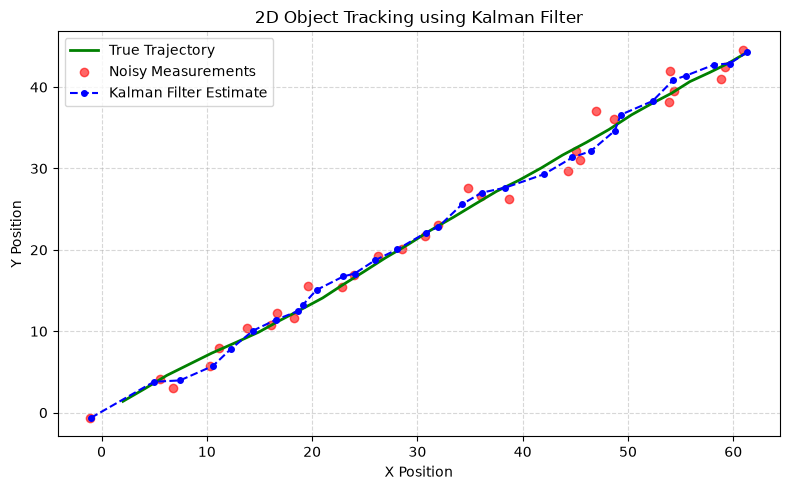

In [14]:
# Practical 7: Implement a simple Kalman Filter to track an object's position in a 2D space (simulate the object's movement with random noise).

import numpy as np
import matplotlib.pyplot as plt

def simulate_and_track_2d(num_steps=30, dt=1.0, seed=42):
    rng = np.random.default_rng(seed)

    # True initial state: [x=0, y=0, vx=2.0, vy=1.5]
    true_state = np.array([0.0, 0.0, 2.0, 1.5])
    F = np.array([[1, 0, dt, 0],
                  [0, 1, 0, dt],
                  [0, 0, 1,  0],
                  [0, 0, 0,  1]], dtype=float)
    H = np.array([[1, 0, 0, 0],
                  [0, 1, 0, 0]], dtype=float)

    # Kalman Filter initialization
    x_est = np.array([[0.0], [0.0], [0.0], [0.0]])
    P = np.eye(4) * 50.0
    Q = np.eye(4) * 0.05
    R = np.eye(2) * 2.5  # Measurement noise covariance

    true_positions, noisy_measurements, filtered_positions = [], [], []

    for _ in range(num_steps):
        # Simulate true object motion with slight process jitter
        true_state = F @ true_state + rng.normal(0, 0.1, size=4)
        z = H @ true_state + rng.normal(0, np.sqrt(2.5), size=2)

        # Kalman Predict
        x_pred = F @ x_est
        P_pred = F @ P @ F.T + Q

        # Kalman Update
        y = z.reshape(2, 1) - H @ x_pred
        S = H @ P_pred @ H.T + R
        K = P_pred @ H.T @ np.linalg.inv(S)
        x_est = x_pred + K @ y
        P = (np.eye(4) - K @ H) @ P_pred

        true_positions.append(true_state[:2].copy())
        noisy_measurements.append(z.copy())
        filtered_positions.append(x_est[:2].flatten().copy())

    return np.array(true_positions), np.array(noisy_measurements), np.array(filtered_positions)

true_pts, meas_pts, est_pts = simulate_and_track_2d(num_steps=30)

meas_rmse = np.sqrt(np.mean(np.sum((true_pts - meas_pts) ** 2, axis=1)))
kf_rmse = np.sqrt(np.mean(np.sum((true_pts - est_pts) ** 2, axis=1)))

print(f"Raw Measurement RMSE : {meas_rmse:.3f}")
print(f"Kalman Filtered RMSE : {kf_rmse:.3f}")

plt.figure(figsize=(8, 5))
plt.plot(true_pts[:, 0], true_pts[:, 1], 'g-', linewidth=2, label='True Trajectory')
plt.scatter(meas_pts[:, 0], meas_pts[:, 1], c='r', alpha=0.6, label='Noisy Measurements')
plt.plot(est_pts[:, 0], est_pts[:, 1], 'b--o', markersize=4, label='Kalman Filter Estimate')
plt.title("2D Object Tracking using Kalman Filter")
plt.xlabel("X Position")
plt.ylabel("Y Position")
plt.legend()
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()